In [1]:
import numpy as np
import matplotlib.pyplot as plt
import joblib 
import astropy
from astropy import convolution
import torch
from tqdm import tqdm
from utils import SimpleDatasetMaker, ratemap_collage
import scipy


In [2]:
# Optimization model
class OptimizationModel:
    def __init__(self, d = 256):
        self.A = (0.01*torch.rand((d, d))).requires_grad_()
        self.B = (0.01*torch.rand((d, d))).requires_grad_()
        self.d = d
        self.optimizer = torch.optim.Adam([self.A, self.B], lr=0.001)

    def objective_function(self, p0, pt, dr):
        # Compute e^(A + B)
        C = torch.matrix_exp(dr[...,0, None, None]*self.A[None] + dr[...,1,None,None]*self.B[None])
        p_pred = torch.bmm(C, p0[...,None]).squeeze()
        # require commutation
        commutation_loss = torch.mean((self.A@self.B - self.B@self.A)**2)
        return torch.mean((pt - p_pred)**2) + commutation_loss

    def optimize(self, n, ratemaps, bs = 33):
        self.loss_history = []

        for _ in tqdm(range(n)):
            self.optimizer.zero_grad()  # Clear previous gradients
            i0 = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))
            # it = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))

            di = torch.randint(-2, 2, size = (bs, 2))
            
            i_trial = i0 + di
            mask = torch.abs(i_trial - (ratemaps.shape[0]-1)/2) > ((ratemaps.shape[0]-1)/2)
            di = -di*mask + di*(~mask)
            it = i0 + di

            # it = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))
            di = it - i0
            dr = (2/ratemaps.shape[0])*di.float()

            loss = self.objective_function(ratemaps[i0[:,0], i0[:,1]], ratemaps[it[:,0], it[:,1]], dr)  # Compute the loss
            loss.backward()  # Backpropagation
            self.optimizer.step()  # Update parameters
            self.loss_history.append(loss.item())
        return self.loss_history


torch.Size([32, 32, 102])

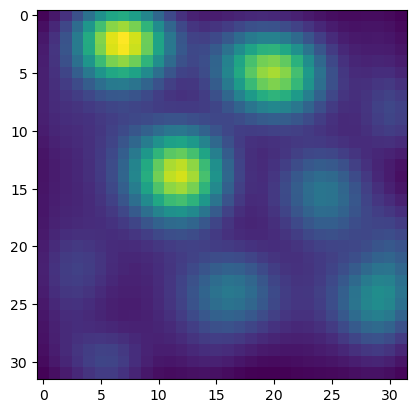

In [3]:
# load data
original_ratemaps = np.load("gc_ratmaps.npy").astype("float32")
original_ratemaps = np.transpose(original_ratemaps, (1,2,0))
plt.imshow(original_ratemaps[...,0])

ratemaps = torch.tensor(original_ratemaps)
ratemaps.shape

In [4]:
# place data
# place_ratemaps = joblib.load("./QLAK-CA1-50_rate_maps")["maps"]["smoothed"][...,0]

# nan_mask = np.isnan(np.mean(place_ratemaps, axis = (0, 1))) # remove all-nan maps
# original_ratemaps = place_ratemaps[...,~nan_mask]
# # remove nans
# original_ratemaps = np.array([astropy.convolution.convolve(original_ratemaps[...,i], astropy.convolution.Gaussian2DKernel(1), boundary='extend') for i in range(original_ratemaps.shape[-1])])
# original_ratemaps = np.transpose(original_ratemaps, (1, 2, 0))

# ratemaps = torch.tensor(original_ratemaps.astype("float32"))[...,:100]#[4:-4, 4:-4]
# plt.imshow(torch.linalg.norm(ratemaps, dim =-1), vmin = 0)
# plt.colorbar()
# ax = ratemap_collage(ratemaps.numpy().transpose(2, 0, 1)[:100], 10)
# print(place_ratemaps.shape, original_ratemaps.shape, ratemaps.shape)


In [5]:
model = OptimizationModel(d = ratemaps.shape[-1])

In [6]:
loss_history = model.optimize(20000, ratemaps)

100%|██████████| 20000/20000 [10:02<00:00, 33.19it/s]


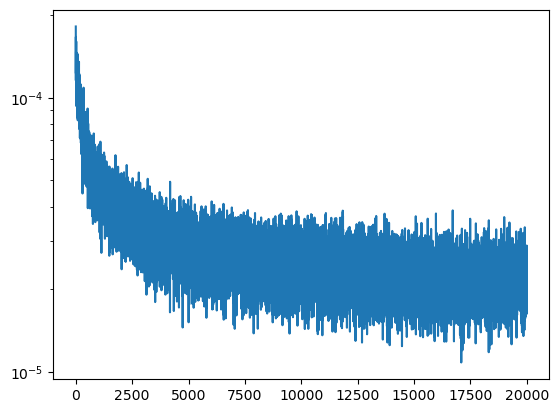

In [7]:
plt.semilogy(model.loss_history)

In [8]:
genny = SimpleDatasetMaker(rayleigh_scale=0.1, chamber_size=1) # trajectory dataset generator

steps = 10000
r, v = genny.generate_dataset(100, steps)
ind = torch.argmin(torch.linalg.norm(r[:,0], axis=  -1)) # center!
r = r[ind]
v = v[ind]
r = r.squeeze()
v = v.squeeze()
# shift to center to compare with ratemaps
r = r - r[0,None]

(-1.0272114723920822,
 1.1721750348806381,
 -1.2607113540172576,
 0.9379787862300872)

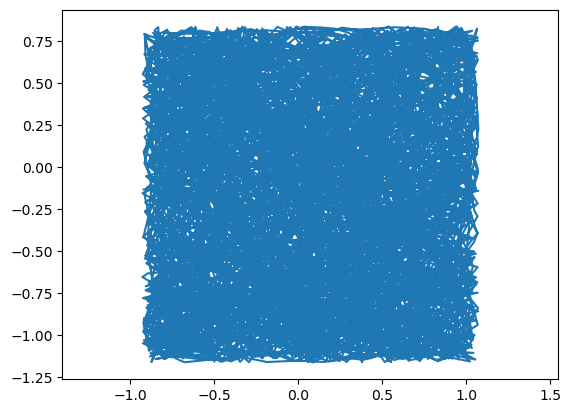

In [9]:
plt.plot(r[:,0], r[:,1])
plt.axis("equal")

In [10]:
# only generation 
p_prime = torch.full((ratemaps.shape[-1], steps), torch.nan, dtype = torch.float32)
p_prime[:,0] = ratemaps[ratemaps.shape[0]//2,ratemaps.shape[1]//2]

for i in range(steps-1):
    z = p_prime[:,i]
    dr = v[i]
    theta = np.arctan2(dr[1], dr[0])
    m = torch.sqrt(dr[0]**2 + dr[1]**2)
    C = dr[0]*model.A + dr[1]*model.B
    Q = torch.matrix_exp(C)
    p_prime[:,i+1] = Q@z

p_prime = p_prime.detach().numpy()

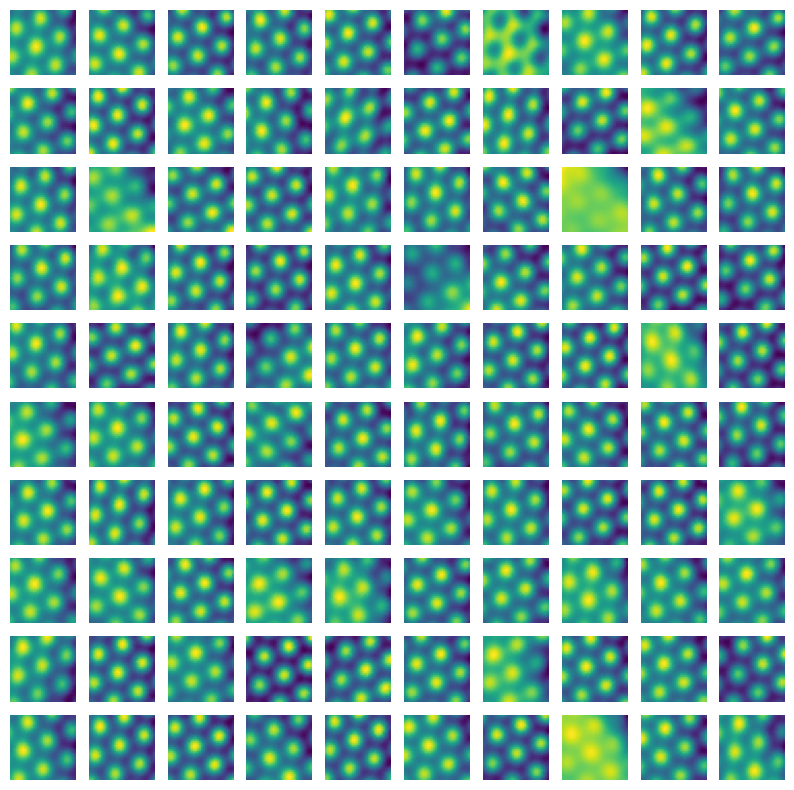

In [11]:
bins = original_ratemaps.shape[0]
pp_prime = scipy.stats.binned_statistic_2d(r[:,0], r[:,1], p_prime, bins = 32)[0]

R = lambda x: np.maximum(0, x) # relu
if relu := False:
    pp_prime = R(pp_prime)
fig, axs = ratemap_collage(pp_prime[:100],10, figsize = (10, 10))

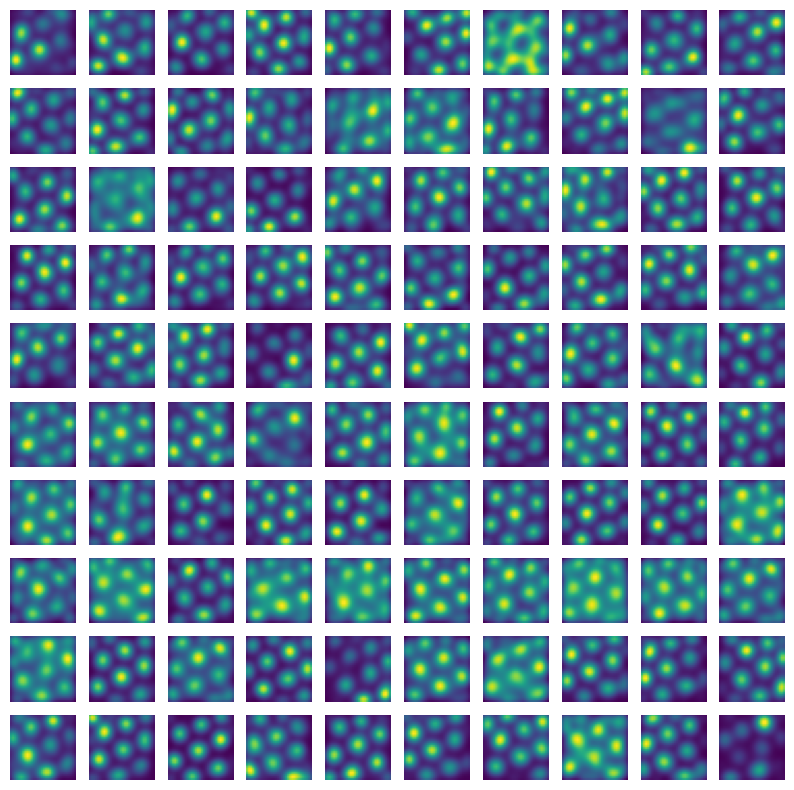

In [12]:
ratemap_collage(original_ratemaps.transpose(2, 0, 1)[:100], 10, figsize = (10,10));

Text(0.5, 1.0, 'Learned Norm')

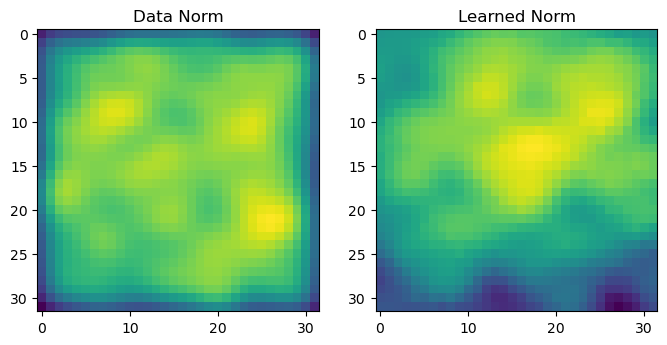

In [13]:
fig, ax = plt.subplots(1, 2, figsize = (8, 4))
ax[0].imshow(np.linalg.norm(ratemaps, axis = -1))
ax[1].imshow(np.linalg.norm(pp_prime, axis = 0))
ax[0].set_title("Data Norm")
ax[1].set_title("Learned Norm")

Text(0.5, 1.0, 'Learned')

<Figure size 500x500 with 0 Axes>

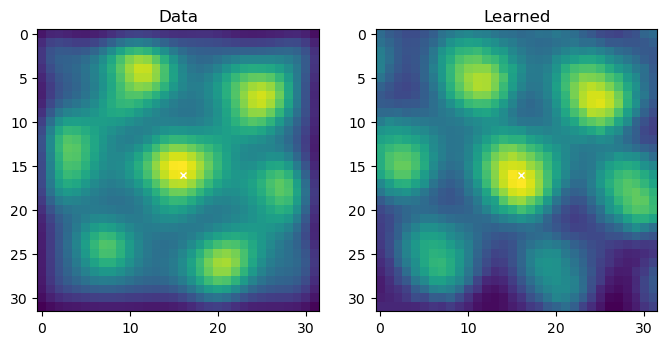

In [14]:
plt.figure(figsize = (5,5))
a = original_ratemaps.shape[0]//2 
b = original_ratemaps.shape[1]//2 

dp_data = np.nansum((original_ratemaps*original_ratemaps[a,b,None,None])**2,axis=-1)
dp_learned = np.nansum((pp_prime*pp_prime[:,pp_prime.shape[-1]//2,pp_prime.shape[-1]//2,None,None])**2,axis=0)

fig, ax = plt.subplots(1, 2, figsize = (8, 4))
ax[0].imshow(dp_data)
ax[1].imshow(dp_learned)
ax[0].plot(b,a, "wx", markersize = 5)
ax[1].plot(pp_prime.shape[-1]//2,pp_prime.shape[-1]//2, "wx", markersize = 5)
ax[0].set_title("Data")
ax[1].set_title("Learned")

In [15]:
A_eigs = np.linalg.eigvals(model.A.detach().numpy())
B_eigs = np.linalg.eigvals(model.B.detach().numpy())

Text(0, 0.5, 'Im')

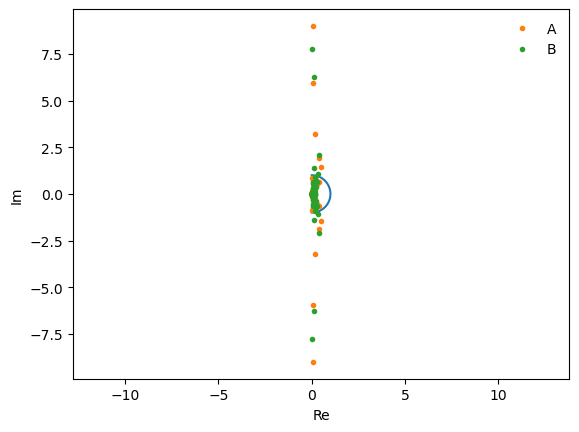

In [16]:
theta = np.linspace(-np.pi/2, np.pi/2, 100)
plt.plot(np.cos(theta), np.sin(theta))

plt.plot(A_eigs.real, A_eigs.imag, ".", label = "A")
plt.plot(B_eigs.real, B_eigs.imag, ".", label = "B")
plt.legend(frameon = False)
plt.axis("equal")
plt.xlabel("Re")
plt.ylabel("Im")

(-0.03267347326036543,
 0.544982047076337,
 -0.023774613277055323,
 0.40651498187799007)

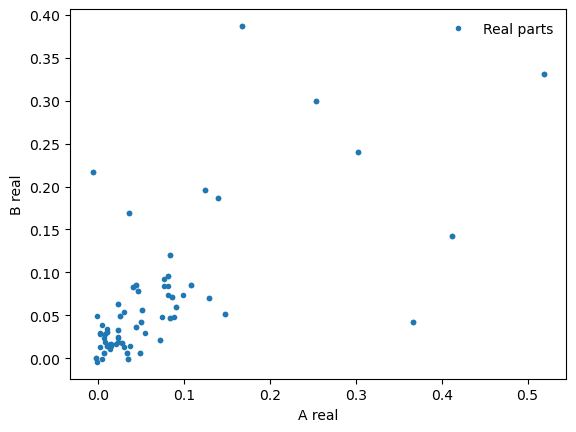

In [17]:
plt.plot(A_eigs.real, B_eigs.real, ".", label = "Real parts")
plt.xlabel("A real")
plt.ylabel("B real")
plt.legend(frameon = False)
plt.axis("equal")

(-9.898381328582763, 9.898381328582763, -8.530210065841676, 8.530210065841676)

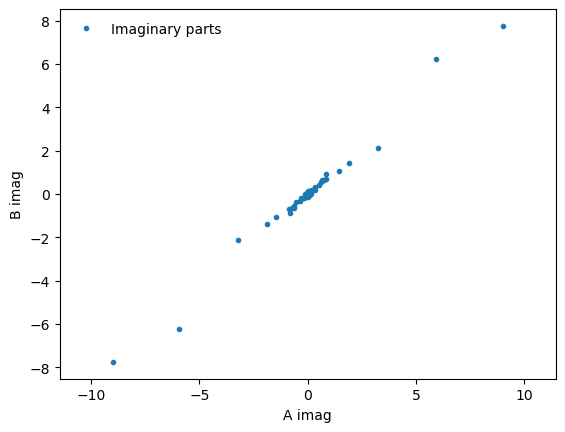

In [18]:
plt.plot(A_eigs.imag, B_eigs.imag, ".", label = "Imaginary parts")
plt.xlabel("A imag")
plt.ylabel("B imag")
plt.legend(frameon = False)
plt.axis("equal")

(array([ 1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,
         2.,  5., 36., 46.,  5.,  2.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  1.,  0.,  0.,  1.]),
 array([-7.75473642, -7.27006531, -6.78539419, -6.30072355, -5.81605244,
        -5.33138132, -4.84671021, -4.36203909, -3.87736821, -3.3926971 ,
        -2.90802622, -2.4233551 , -1.93868411, -1.45401311, -0.96934205,
        -0.48467103,  0.        ,  0.48467103,  0.96934205,  1.45401311,
         1.93868411,  2.4233551 ,  2.90802622,  3.3926971 ,  3.87736821,
         4.36203909,  4.84671021,  5.33138132,  5.81605244,  6.30072355,
         6.78539419,  7.27006531,  7.75473642]),
 <BarContainer object of 32 artists>)

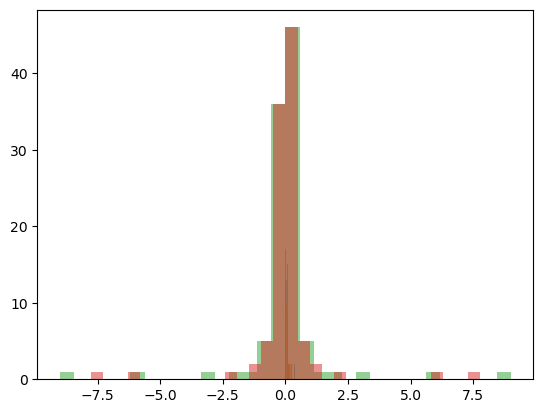

In [19]:
plt.hist(A_eigs.real, bins = 32, alpha = 0.5)
plt.hist(B_eigs.real, bins = 32, alpha = 0.5)    
plt.hist(A_eigs.imag, bins = 32, alpha = 0.5)
plt.hist(B_eigs.imag, bins = 32, alpha = 0.5)

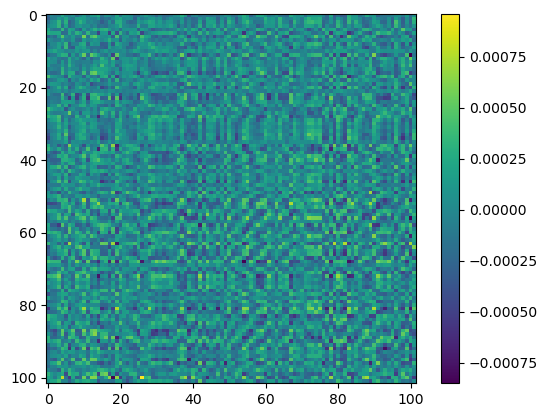

In [20]:
commutator = model.A@model.B - model.B@model.A
plt.imshow(commutator.detach().numpy())
plt.colorbar()

(array([  3.,   1.,   0.,   1.,   1.,   1.,   2.,   4.,   5.,   5.,   5.,
          9.,  11.,  14.,  12.,  15.,  18.,  25.,  24.,  34.,  51.,  53.,
         58.,  60.,  63.,  73.,  91.,  91., 121., 141., 142., 161., 193.,
        225., 199., 211., 241., 240., 259., 272., 276., 297., 286., 288.,
        307., 308., 279., 277., 263., 274., 303., 259., 289., 292., 264.,
        272., 251., 255., 227., 209., 186., 194., 186., 185., 153., 134.,
        106., 110.,  82.,  83.,  51.,  44.,  55.,  40.,  33.,  33.,  28.,
         11.,  19.,  14.,   6.,   9.,   6.,   7.,   3.,   7.,   0.,   4.,
          2.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([-8.51906836e-04, -8.33774160e-04, -8.15641426e-04, -7.97508750e-04,
        -7.79376016e-04, -7.61243340e-04, -7.43110606e-04, -7.24977930e-04,
        -7.06845196e-04, -6.88712520e-04, -6.70579844e-04, -6.52447110e-04,
        -6.34314434e-04, -6.16181700e-04, -5.98049024e-04, -5.79916290e-04,
        -5.617

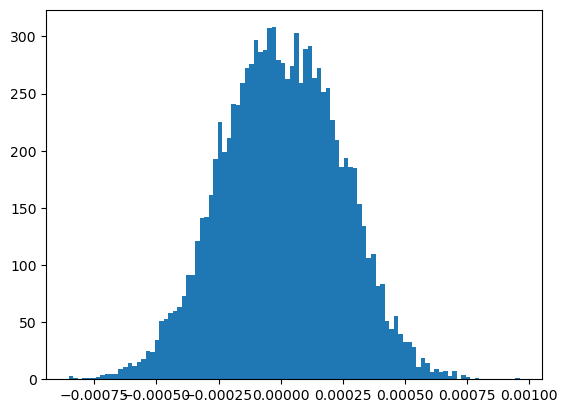

In [21]:
plt.hist(commutator.detach().numpy().flatten(), bins = 100)